# Control óptimo de EDOs — Clase 2
**El problema básico y el Principio del Máximo**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

En casi todo este notebook resolvemos el **problema de valores de frontera** que da el PMP con
`scipy.integrate.solve_bvp`: le pasamos el sistema para $(x,\lambda)$ (con $u$ ya despejado de $H_u=0$),
las condiciones de borde como residuos y una semilla. Después **chequeamos**: solución exacta, $H$ constante
(problemas autónomos) y concavidad.

## 1. Multiplicadores de Lagrange y precio sombra
$\max y_1y_2$ sujeto a $y_1+y_2=c$. A mano: $y_1=y_2=c/2$, $\lambda=-c/2$, $F^*(c)=c^2/4$ y $\frac{dF^*}{dc}=-\lambda$.

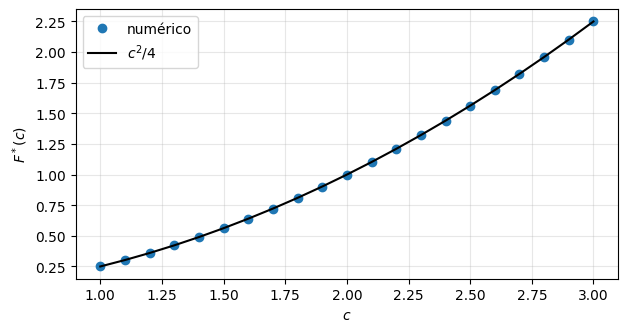

c=2: y* = [1. 1.], lambda = -1.0000
dF*/dc (diferencias finitas) = 1.0000   -lambda = 1.0000   (precio sombra)


In [2]:
def resolver(c):
    r = minimize(lambda y: -y[0]*y[1], x0=[0.3, 0.7], method='SLSQP',
                 constraints=[{'type': 'eq', 'fun': lambda y: y[0] + y[1] - c}])
    y = r.x
    return y, -r.fun, -y[1]           # lambda de la condición  y2 + lambda = 0

cs = np.linspace(1, 3, 21)
plt.plot(cs, [resolver(c)[1] for c in cs], 'o', label='numérico'); plt.plot(cs, cs**2/4, 'k-', label='$c^2/4$')
plt.xlabel('$c$'); plt.ylabel('$F^*(c)$'); plt.legend(); plt.show()
y, F2, lam = resolver(2.0); h = 1e-4
dF = (resolver(2 + h)[1] - resolver(2 - h)[1])/(2*h)
print(f'c=2: y* = {y}, lambda = {lam:.4f}')
print(f'dF*/dc (diferencias finitas) = {dF:.4f}   -lambda = {-lam:.4f}   (precio sombra)')

## 2. Ejemplo 1: $\max\int_0^1(x-u^2)$, $\dot x=u$, $x(0)=0$
PMP: $u=\lambda/2$, $\dot\lambda=-1$, $\lambda(1)=0$. A mano: $\lambda=1-t$, $u^*=\frac{1-t}{2}$, $x^*=\frac t2-\frac{t^2}4$, $H\equiv\frac14$.

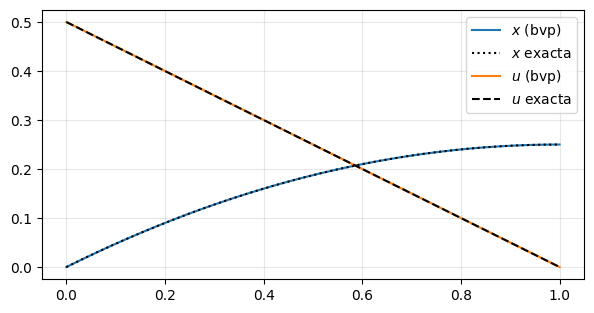

error máx en u: 2.220446049250313e-16 |  H min/max: 0.25000000000000006 0.25000000000000033 (teoría 1/4)


In [3]:
def sistema1(t, y):                    # y = (x, lambda)
    x, lam = y
    return np.vstack([lam/2, -np.ones_like(lam)])

bordes1 = lambda ya, yb: np.array([ya[0] - 0.0, yb[1] - 0.0])    # x(0)=0, lambda(1)=0  (residuos)
t = np.linspace(0, 1, 50)
sol1 = solve_bvp(sistema1, bordes1, t, np.zeros((2, t.size)))
tt = np.linspace(0, 1, 300); x1, l1 = sol1.sol(tt); u1 = l1/2
plt.plot(tt, x1, label='$x$ (bvp)'); plt.plot(tt, tt/2 - tt**2/4, 'k:', label='$x$ exacta')
plt.plot(tt, u1, label='$u$ (bvp)'); plt.plot(tt, (1 - tt)/2, 'k--', label='$u$ exacta')
plt.legend(); plt.show()
H1 = x1 - u1**2 + l1*u1
print('error máx en u:', np.abs(u1 - (1 - tt)/2).max(), '|  H min/max:', H1.min(), H1.max(), '(teoría 1/4)')

## 3. Ejemplo 1': dos controles
$\max\int_0^1(x-c_1u_1^2-c_2u_2^2)$, $\dot x=b_1u_1+b_2u_2$, $x(0)=0$.
PMP: $u_i^*=\frac{b_i}{2c_i}\lambda$, $\lambda=1-t$; con $K=\frac{b_1^2}{2c_1}+\frac{b_2^2}{2c_2}$: $x^*=K(t-\frac{t^2}2)$, $H\equiv\frac K2$.

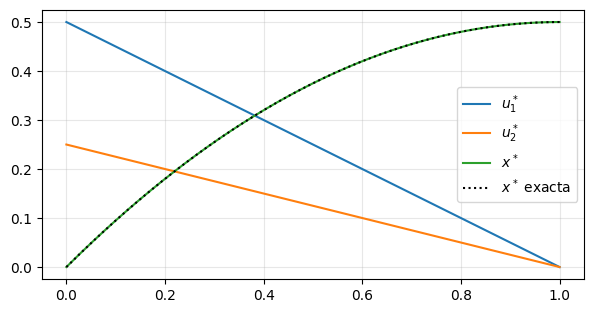

u1/u2 = 2.0   teoría (b1/c1)/(b2/c2) = 2.0
H min/max: 0.5000000000000001 0.5000000000000007   teoría K/2 = 0.5


/tmp/ipykernel_207/2569742747.py:11: RuntimeWarning: invalid value encountered in divide
  print('u1/u2 =', (u1b/u2b)[:-1].mean(), '  teoría (b1/c1)/(b2/c2) =', (b1/c1)/(b2/c2))


In [4]:
b1, c1, b2, c2 = 1.0, 1.0, 2.0, 4.0
def sistema1b(t, y):
    x, lam = y
    u1, u2 = b1*lam/(2*c1), b2*lam/(2*c2)
    return np.vstack([b1*u1 + b2*u2, -np.ones_like(lam)])
sol1b = solve_bvp(sistema1b, bordes1, t, np.zeros((2, t.size)))
xb, lb = sol1b.sol(tt); u1b, u2b = b1*lb/(2*c1), b2*lb/(2*c2)
K = b1**2/(2*c1) + b2**2/(2*c2)
plt.plot(tt, u1b, label='$u_1^*$'); plt.plot(tt, u2b, label='$u_2^*$'); plt.plot(tt, xb, label='$x^*$')
plt.plot(tt, K*(tt - tt**2/2), 'k:', label='$x^*$ exacta'); plt.legend(); plt.show()
print('u1/u2 =', (u1b/u2b)[:-1].mean(), '  teoría (b1/c1)/(b2/c2) =', (b1/c1)/(b2/c2))
Hb = xb - c1*u1b**2 - c2*u2b**2 + lb*(b1*u1b + b2*u2b)
print('H min/max:', Hb.min(), Hb.max(), '  teoría K/2 =', K/2)

## 4. Ejemplo 2: carro a cohete, estado en $\mathbb R^2$
$\max\int_0^1(x_1-\frac12u^2)$, $\dot x_1=x_2$, $\dot x_2=u$, $x(0)=(0,0)$.
PMP: $\dot\lambda_1=-1$, $\dot\lambda_2=-\lambda_1$, $\lambda(1)=(0,0)$, $u^*=\lambda_2$.
Ahora el sistema tiene **4** ecuaciones y **4** condiciones de borde (dos en $t=0$ y dos en $t=1$).

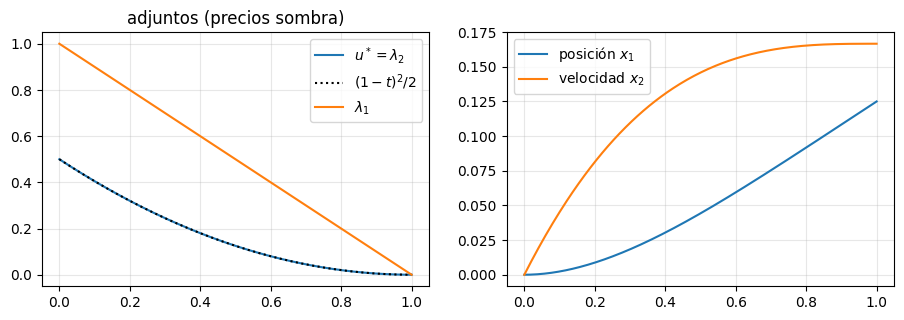

x(1) = [0.125      0.16666667]   teoría (1/8, 1/6)  |  H min/max: 0.12499999954827448 0.12500000000000014 (teoría 1/8)


In [5]:
def sistema2(t, y):                    # y = (x1, x2, lambda1, lambda2)
    x1, x2, l1, l2 = y
    u = l2
    return np.vstack([x2, u, -np.ones_like(l1), -l1])

bordes2 = lambda ya, yb: np.array([ya[0], ya[1], yb[2], yb[3]])   # x(0)=(0,0), lambda(1)=(0,0)
sol2 = solve_bvp(sistema2, bordes2, t, np.zeros((4, t.size)))
X1, X2, L1, L2 = sol2.sol(tt)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(tt, L2, label='$u^*=\\lambda_2$'); ax[0].plot(tt, (1 - tt)**2/2, 'k:', label='$(1-t)^2/2$')
ax[0].plot(tt, L1, label='$\\lambda_1$'); ax[0].legend(); ax[0].set_title('adjuntos (precios sombra)')
ax[1].plot(tt, X1, label='posición $x_1$'); ax[1].plot(tt, X2, label='velocidad $x_2$'); ax[1].legend()
plt.show()
H2 = X1 - 0.5*L2**2 + L1*X2 + L2*L2
print('x(1) =', sol2.sol(1)[:2], '  teoría (1/8, 1/6)  |  H min/max:', H2.min(), H2.max(), '(teoría 1/8)')

## 5. Ejemplo 3: $\min\frac12\int_0^1(3x^2+u^2)$, $\dot x=x+u$, $x(0)=1$
Como máximo: $u=\lambda$, $\dot\lambda=3x-\lambda$, $\lambda(1)=0$: el sistema lineal con la matriz $\begin{pmatrix}1&1\\3&-1\end{pmatrix}$ de la Clase 1.

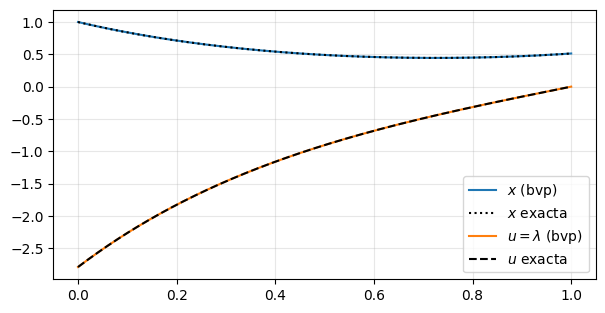

error máx en u: 2.254521769273765e-08
H min/max: -0.39497727189235654 -0.3949772661820682   teoría -3/2 x(1)^2 = -0.3949772664359733


In [6]:
sistema3 = lambda t, y: np.vstack([y[0] + y[1], 3*y[0] - y[1]])
sol3 = solve_bvp(sistema3, lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]), t, np.zeros((2, t.size)))
c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
x_ex = c*np.exp(2*tt) + d*np.exp(-2*tt); u_ex = c*np.exp(2*tt) - 3*d*np.exp(-2*tt)
x3, l3 = sol3.sol(tt)
plt.plot(tt, x3, label='$x$ (bvp)'); plt.plot(tt, x_ex, 'k:', label='$x$ exacta')
plt.plot(tt, l3, label='$u=\\lambda$ (bvp)'); plt.plot(tt, u_ex, 'k--', label='$u$ exacta')
plt.legend(); plt.show()
H3 = -1.5*x3**2 - 0.5*l3**2 + l3*(x3 + l3)
print('error máx en u:', np.abs(l3 - u_ex).max())
print('H min/max:', H3.min(), H3.max(), '  teoría -3/2 x(1)^2 =', -1.5*x_ex[-1]**2)

### ¿Algún control le gana al del PMP?
Simulamos controles perturbados $u^*+0.6\,(\text{perturbación aleatoria})$ y calculamos el costo (a minimizar).

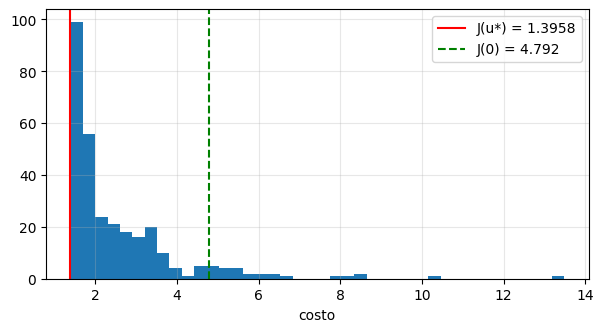

mínimo de los perturbados: 1.402583820253548


In [7]:
tg = np.linspace(0, 1, 2001)
u_opt = c*np.exp(2*tg) - 3*d*np.exp(-2*tg)

def costo3(u):
    s = solve_ivp(lambda s, x: x + np.interp(s, tg, u), [0, 1], [1.0], t_eval=tg, rtol=1e-9)
    return 0.5*integral(3*s.y[0]**2 + u**2, tg)

rng = np.random.default_rng(0)
vals = [costo3(u_opt + 0.6*(a[0] + a[1]*tg + a[2]*np.sin(np.pi*tg) + a[3]*np.cos(3*tg)))
        for a in rng.normal(size=(300, 4))]
plt.hist(vals, bins=40); plt.axvline(costo3(u_opt), color='r', label=f'J(u*) = {costo3(u_opt):.4f}')
plt.axvline(costo3(0*tg), color='g', ls='--', label=f'J(0) = {costo3(0*tg):.3f}')
plt.legend(); plt.xlabel('costo'); plt.show()
print('mínimo de los perturbados:', min(vals))

## 6. Ejemplo 4: el PMP da candidatos, no garantías
$\max\int_0^1u^2$, $\dot x=u$. El único candidato es $u\equiv0$, pero $J(k)=k^2\to\infty$: no hay máximo.

In [8]:
for k in [0, 1, 2, 5, 10]:
    print(f'u = {k:3d}:  J = {integral(np.full_like(tg, k)**2, tg):8.2f}')
print('H_uu = 2 > 0: viola Legendre-Clebsch para un máximo. Para el MÍNIMO, u=0 sí es óptimo (H=-u^2+lam u es cóncava).')

u =   0:  J =     0.00
u =   1:  J =     1.00
u =   2:  J =     4.00
u =   5:  J =    25.00
u =  10:  J =   100.00
H_uu = 2 > 0: viola Legendre-Clebsch para un máximo. Para el MÍNIMO, u=0 sí es óptimo (H=-u^2+lam u es cóncava).


## 7. Ejercicios 1 y 2
**Ejercicio 1:** $\min\int_0^1(x^2+u^2)$, $\dot x=u$, $x(0)=1$. Se espera $x^*=\cosh(1-t)/\cosh1$ y $u^*(0)=-\tanh 1$.

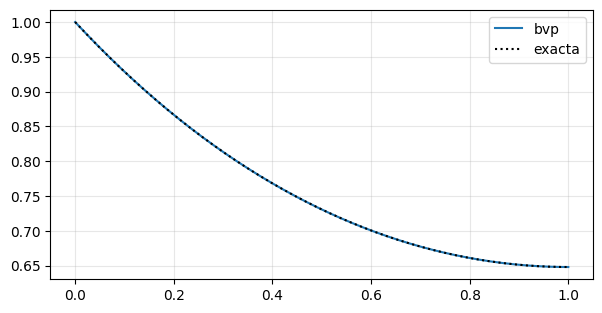

u*(0) = -0.7615941558545799    -tanh(1) = -0.7615941559557649


In [9]:
# H = -x^2 - u^2 + lam*u  ->  u = lam/2,  lam' = 2x
sol_e1 = solve_bvp(lambda t, y: np.vstack([y[1]/2, 2*y[0]]),
                   lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]), t, np.zeros((2, t.size)))
plt.plot(tt, sol_e1.sol(tt)[0], label='bvp'); plt.plot(tt, np.cosh(1 - tt)/np.cosh(1), 'k:', label='exacta')
plt.legend(); plt.show()
print('u*(0) =', sol_e1.sol(0)[1]/2, '   -tanh(1) =', -np.tanh(1))

**Ejercicio 2:** $\max\int_0^2(x-2u^2)$, $\dot x=-x+u$, $x(0)=1$. Completar el sistema y comparar con la solución a mano
($\lambda=1-e^{t-2}$, $u^*=\lambda/4$).

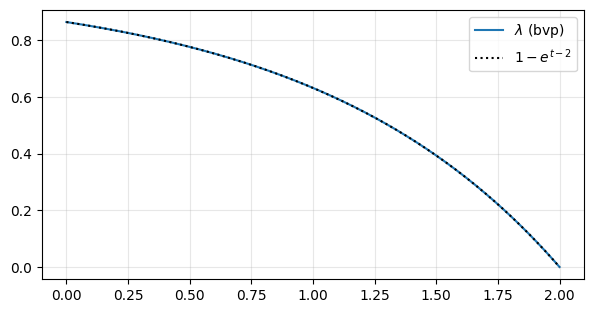

In [10]:
# H = x - 2u^2 + lam(-x + u)
def sistema_e2(t, y):
    x, lam = y
    u = lam/4
    return np.vstack([-x + u, -1 + lam])          # lam' = -H_x = -1 + lam

t2 = np.linspace(0, 2, 60)
sol_e2 = solve_bvp(sistema_e2, lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]), t2, np.zeros((2, t2.size)))
tt2 = np.linspace(0, 2, 300)
plt.plot(tt2, sol_e2.sol(tt2)[1], label='$\\lambda$ (bvp)'); plt.plot(tt2, 1 - np.exp(tt2 - 2), 'k:', label='$1-e^{t-2}$')
plt.legend(); plt.show()

## 8. Ejercicio 6 (numérico): dosis de carga y de mantenimiento
$\min\int_0^T\big((x-\bar x)^2+c\,u^2\big)$, $\dot x=-\frac{Vx}{K+x}+u$, $x(0)=0$.

Como máximo: $H=-(x-\bar x)^2-cu^2+\lambda\big(-\frac{Vx}{K+x}+u\big)$, así que $u^*=\frac{\lambda}{2c}$ y
$\dot\lambda=-H_x=2(x-\bar x)+\lambda\frac{VK}{(K+x)^2}$, $\lambda(T)=0$.

El sistema es **no lineal**: no se resuelve a mano. Ayuda: dar como semilla $x\equiv\bar x$
(en problemas no lineales Newton necesita empezar cerca).

The algorithm converged to the desired accuracy.


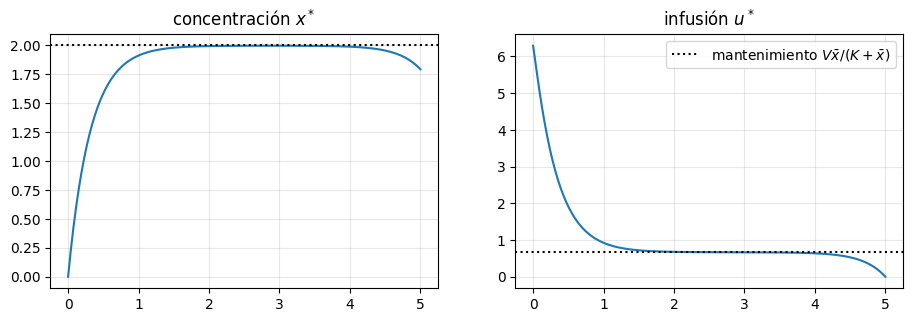

u*(0) = 6.2893643297998585 |  H min/max: -0.04438963270411733 -0.04438959646401329


In [11]:
V, Km, xbar, c6, T6 = 1.0, 1.0, 2.0, 0.1, 5.0

def sistema6(t, y):
    x, lam = y
    u = lam/(2*c6)
    return np.vstack([-V*x/(Km + x) + u, 2*(x - xbar) + lam*V*Km/(Km + x)**2])

t6 = np.linspace(0, T6, 200)
semilla = np.vstack([np.full_like(t6, xbar), np.zeros_like(t6)])
sol6 = solve_bvp(sistema6, lambda ya, yb: np.array([ya[0] - 0.0, yb[1]]), t6, semilla, tol=1e-6, max_nodes=20000)
print(sol6.message)
tt6 = np.linspace(0, T6, 400); x6, l6 = sol6.sol(tt6); u6 = l6/(2*c6)
u_mant = V*xbar/(Km + xbar)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(tt6, x6); ax[0].axhline(xbar, ls=':', c='k'); ax[0].set_title('concentración $x^*$')
ax[1].plot(tt6, u6); ax[1].axhline(u_mant, ls=':', c='k', label='mantenimiento $V\\bar x/(K+\\bar x)$')
ax[1].set_title('infusión $u^*$'); ax[1].legend()
plt.show()
H6 = -(x6 - xbar)**2 - c6*u6**2 + l6*(-V*x6/(Km + x6) + u6)
print('u*(0) =', u6[0], '|  H min/max:', H6.min(), H6.max())

**Para interpretar:** (1) *dosis de carga* al principio para llegar rápido a $\bar x$; (2) *mantenimiento* con
$u\approx V\bar x/(K+\bar x)$, que compensa la eliminación; (3) al final la infusión baja a $0$ porque
$\lambda(T)=0$: lo que pase después de $T$ no cuenta. Probar con $T=10$, $c=1$ y $c=0.01$.

## Para explorar
1. En el Ejemplo 1', cambiar $b_i$ y $c_i$ y verificar que el cociente $u_1^*/u_2^*$ es siempre $(b_1/c_1)/(b_2/c_2)$.
2. En el Ejemplo 2, cambiar el costo por $\frac c2u^2$: ¿cómo escala la distancia final con $c$?
3. En el Ejemplo 3, verificar que $H$ es constante también con $T=2$.
4. En la sección 1, cambiar el objetivo por $\max y_1^2y_2$ y repetir el chequeo del precio sombra.